# 02 — QAOA Max-Cut Quality using Qiskit

**Project:** QFlowPilot

**Research Area:** Quality-Aware Quantum-Classical Runtime Systems

## Objective

The purpose of this notebook is to implement the Quantum Approximate
Optimization Algorithm (QAOA) for the Max-Cut problem.

We will use Qiskit to construct quantum circuits and Qiskit Aer
to execute them locally.

The experiment will evaluate the quality of QAOA results using:

1. Expected cut value
2. Approximation ratio
3. Optimal solution probability
4. Comparison with the exact classical solution

We will use a small graph so that its exact optimal solution can
be calculated through classical brute-force enumeration.

**Important:** This notebook uses local Qiskit Aer simulation.
It does not represent real IBM Quantum hardware execution.

https://qiskit.qotlabs.org/docs/tutorials/quantum-approximate-optimization-algorithm?utm_source=chatgpt.com

1. What is the Max-Cut problem?
Max-Cut (Maximum Cut) is a mathematical optimization problem in graph theory.

Its goal is to divide the nodes (vertices) of a graph into two different groups so that the total weight of the edges connecting the two groups is as large as possible.

In simple words:

Imagine you have several people connected through relationships. You want to divide these people into two groups so that the maximum number (or total weight) of connections goes between the two groups.

2. Why are you using Max-Cut in your QAOA notebook?
Your research notebook is studying how to implement and evaluate QAOA using real Qiskit circuits.

Max-Cut is a useful starting problem for this purpose because:
1. Easy to understand: You can represent the problem using nodes, edges, and binary values.
2. Suitable for QAOA: Max-Cut has a well-established mathematical formulation using quantum Hamiltonians.
3. Hybrid quantum-classical optimization: QAOA uses a quantum circuit to generate candidate solutions and a classical optimizer to improve its parameters.
4. Easy to benchmark: You can calculate the exact optimal answer using a classical algorithm and compare QAOA against it.
5. Measurement analysis: You can study how shot numbers affect the probabilities and quality of measured solutions.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from itertools import product

from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

SEED = 42

rng = np.random.default_rng(SEED)

simulator = AerSimulator(seed_simulator=SEED)

print("QAOA Max-Cut experiment initialized.")
print("Qiskit Aer simulator is ready.")

QAOA Max-Cut experiment initialized.
Qiskit Aer simulator is ready.


## 1. Max-Cut Problem

Max-Cut is a graph optimization problem.

A graph is represented as:

G = (V, E)

Where:

- V represents the vertices (nodes).
- E represents the edges connecting nodes.
- w_ij represents the weight of the edge between nodes i and j.

The objective is to divide the graph vertices into two groups
such that the total weight of edges connecting different groups
is maximized.

Each vertex receives a binary value:

x_i ∈ {0, 1}

If two connected vertices have different binary values,
their connecting edge contributes to the cut value.

## Mathematical Formulation: Max-Cut Problem

The objective of the Max-Cut problem is to divide the vertices of a graph into two groups such that the total weight of edges connecting different groups is maximized.

The cut value is defined as:

$$
C(x)=\sum_{(i,j)\in E} w_{ij}
\frac{1-(-1)^{x_i+x_j}}{2}
$$

### Explanation

- $x_i, x_j$: Binary values assigned to two connected nodes (0 or 1).
- $w_{ij}$: Weight of the edge connecting nodes $i$ and $j$.
- $E$: Set of all edges in the graph.
- $C(x)$: Total weight of the cut.

The expression:

$$
\frac{1-(-1)^{x_i+x_j}}{2}
$$

determines whether two connected nodes belong to different groups.

- If $x_i \neq x_j$, the expression equals 1, and the edge contributes its weight.
- If $x_i = x_j$, the expression equals 0, and the edge contributes nothing.

### Optimization Objective

The goal is to find the binary assignment that maximizes the total cut value:

$$
\boxed{x^*=\arg\max_{x\in\{0,1\}^{|V|}} C(x)}
$$

In [2]:
G = nx.Graph()

G.add_weighted_edges_from([
    (0, 1, 1),
    (0, 2, 2),
    (0, 4, 1),
    (1, 2, 1),
    (1, 3, 2),
    (2, 3, 1),
    (2, 4, 2),
    (3, 4, 1)
])

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nGraph edges and weights:")

for u, v, data in G.edges(data=True):
    print(f"({u}, {v}) -> weight = {data['weight']}")

Nodes: 5
Edges: 8

Graph edges and weights:
(0, 1) -> weight = 1
(0, 2) -> weight = 2
(0, 4) -> weight = 1
(1, 2) -> weight = 1
(1, 3) -> weight = 2
(2, 3) -> weight = 1
(2, 4) -> weight = 2
(4, 3) -> weight = 1


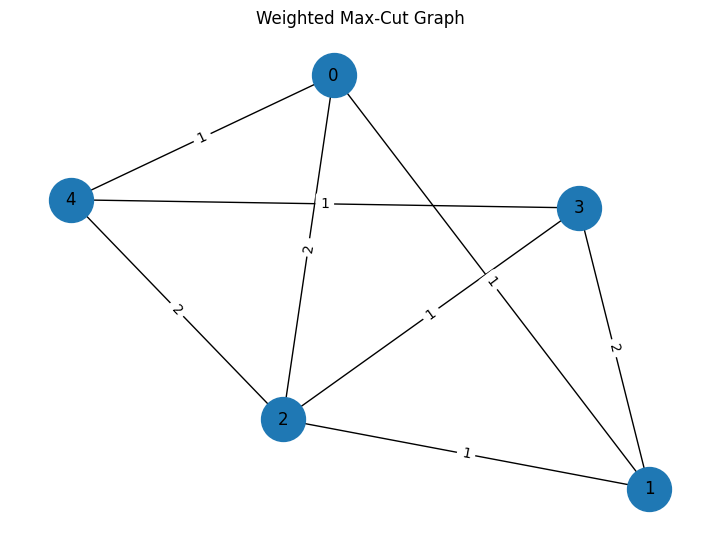

In [3]:
plt.figure(figsize=(7, 5))

pos = nx.spring_layout(G, seed=SEED)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Weighted Max-Cut Graph")
plt.axis("off")
plt.show()

In [4]:
def calculate_cut_value(graph, assignment):

    nodes = sorted(graph.nodes())

    node_index = {
        node: index
        for index, node in enumerate(nodes)
    }

    total_cut = 0

    for u, v, data in graph.edges(data=True):

        weight = data.get("weight", 1)

        x_u = assignment[node_index[u]]
        x_v = assignment[node_index[v]]

        if x_u != x_v:
            total_cut += weight

    return total_cut

In [5]:
test_assignment = (0, 0, 1, 1, 0)

test_cut = calculate_cut_value(
    G,
    test_assignment
)

print("Test assignment:", test_assignment)
print("Cut value:", test_cut)

Test assignment: (0, 0, 1, 1, 0)
Cut value: 8


In [6]:
def exact_max_cut(graph):

    nodes = sorted(graph.nodes())

    best_value = -float("inf")

    optimal_assignments = []

    for assignment in product([0, 1], repeat=len(nodes)):

        cut_value = calculate_cut_value(
            graph,
            assignment
        )

        if cut_value > best_value:

            best_value = cut_value

            optimal_assignments = [assignment]

        elif np.isclose(cut_value, best_value):

            optimal_assignments.append(assignment)

    return best_value, set(optimal_assignments)

In [7]:
exact_optimum, optimal_assignments = exact_max_cut(G)

print("Exact classical Max-Cut value:", exact_optimum)

print("\nOptimal assignments:")

for assignment in sorted(optimal_assignments):
    print(assignment)

print("\nNumber of optimal assignments:", len(optimal_assignments))

Exact classical Max-Cut value: 8

Optimal assignments:
(0, 0, 1, 1, 0)
(0, 1, 0, 0, 1)
(0, 1, 1, 0, 0)
(0, 1, 1, 0, 1)
(1, 0, 0, 1, 0)
(1, 0, 0, 1, 1)
(1, 0, 1, 1, 0)
(1, 1, 0, 0, 1)

Number of optimal assignments: 8


## 2. QAOA Mathematical Foundation

QAOA is a hybrid quantum-classical optimization algorithm.

It combines:

1. Quantum circuit execution.
2. Classical parameter optimization.

The algorithm uses two parameter sets:

- Gamma (γ): cost Hamiltonian parameters.
- Beta (β): mixer Hamiltonian parameters.

The QAOA depth is represented by p.

For this experiment, we will use p = 2.

The quantum circuit prepares a superposition, applies cost operations,
and then applies mixer operations.

A classical optimizer adjusts gamma and beta to maximize
the expected Max-Cut value.

## QAOA Mathematical Formulation

### 1. Cost Hamiltonian

The cost Hamiltonian represents the Max-Cut objective in quantum form.

$$
H_C=\sum_{(i,j)\in E}w_{ij}\frac{I-Z_iZ_j}{2}
$$

**Explanation:**
- $E$: Set of edges in the graph.
- $w_{ij}$: Weight of the edge between nodes $i$ and $j$.
- $I$: Identity operator.
- $Z_i,Z_j$: Pauli-Z operators acting on qubits $i$ and $j$.

This Hamiltonian assigns a contribution to each edge. If two connected nodes have different binary values, the edge contributes its weight to the total cut value.

### 2. Mixer Hamiltonian

The mixer Hamiltonian allows QAOA to explore different possible solutions.

$$
H_B=\sum_{i\in V}X_i
$$

**Explanation:**
- $V$: Set of graph vertices.
- $X_i$: Pauli-X operator acting on qubit $i$.

The Pauli-X operator changes the qubit state between $|0\rangle$ and $|1\rangle$. It helps explore different candidate solutions.

### 3. QAOA Quantum State

The QAOA state is constructed by repeatedly applying the cost and mixer operators.

$$
|\gamma,\beta\rangle =
U_B(\beta_p)U_C(\gamma_p)\cdots
U_B(\beta_1)U_C(\gamma_1)|+\rangle^{\otimes n}
$$

Where:

- $p$: Number of QAOA layers.
- $\gamma$: Cost Hamiltonian parameters.
- $\beta$: Mixer Hamiltonian parameters.
- $U_C(\gamma_k)=e^{-i\gamma_k H_C}$: Cost unitary.
- $U_B(\beta_k)=e^{-i\beta_k H_B}$: Mixer unitary.
- $|+\rangle^{\otimes n}$: Initial state, where all qubits are in an equal superposition.

### 4. Optimization Objective

The objective is to find the optimal parameters that maximize the expected cut value.

$$
\boxed{
\max_{\gamma,\beta}
\langle\gamma,\beta|H_C|\gamma,\beta\rangle
}
$$

**Explanation:**

The classical optimizer adjusts the parameters $\gamma$ and $\beta$ to maximize the expected value of the cost Hamiltonian.

The quantum circuit evaluates candidate parameter values, while the classical optimizer uses the measurement results to improve the parameters.

### 5. Overall QAOA Workflow

1. Initialize all qubits in the superposition state.
2. Apply the cost Hamiltonian.
3. Apply the mixer Hamiltonian.
4. Repeat the process for $p$ layers.
5. Measure the quantum circuit.
6. Calculate the expected cut value.
7. Update $\gamma$ and $\beta$ using a classical optimizer.
8. Repeat until the optimization process converges.

In [9]:
def build_qaoa_circuit(
    graph,
    gamma,
    beta,
    measure=False
):

    nodes = sorted(graph.nodes())

    n_qubits = len(nodes)

    node_index = {
        node: index
        for index, node in enumerate(nodes)
    }

    if measure:
        qc = QuantumCircuit(n_qubits, n_qubits)
    else:
        qc = QuantumCircuit(n_qubits)

    # Initial superposition
    for qubit in range(n_qubits):
        qc.h(qubit)

    p = len(gamma)

    for layer in range(p):

        # Cost Hamiltonian
        for u, v, data in graph.edges(data=True):

            weight = data.get("weight", 1)

            qc.rzz(
                -gamma[layer] * weight,
                node_index[u],
                node_index[v]
            )

        # Mixer Hamiltonian
        for qubit in range(n_qubits):

            qc.rx(
                2 * beta[layer],
                qubit
            )

    if measure:

        qc.measure(
            range(n_qubits),
            range(n_qubits)
        )

    return qc

In [10]:
P = 2

initial_gamma = rng.uniform(
    0,
    2 * np.pi,
    P
)

initial_beta = rng.uniform(
    0,
    np.pi,
    P
)

initial_parameters = np.concatenate([
    initial_gamma,
    initial_beta
])

print("Initial gamma:", initial_gamma)
print("Initial beta:", initial_beta)
print("Initial parameters:", initial_parameters)

Initial gamma: [0.59173373 6.13001603]
Initial beta: [2.3911909  2.46949385]
Initial parameters: [0.59173373 6.13001603 2.3911909  2.46949385]


Before using the optimizer, we need an objective function.

We will use Qiskit's Statevector to calculate the ideal expectation value during parameter optimization.

This avoids making the classical optimizer depend on noisy finite-shot estimates at every iteration.

In [11]:
def calculate_expected_cut_statevector(
    graph,
    gamma,
    beta
):

    qc = build_qaoa_circuit(
        graph,
        gamma,
        beta,
        measure=False
    )

    state = Statevector.from_instruction(qc)

    probabilities = state.probabilities_dict()

    expected_cut = 0.0

    for qiskit_bitstring, probability in probabilities.items():

        # Qiskit displays classical-style bitstrings
        # with qubit 0 at the rightmost position.
        bitstring = qiskit_bitstring.replace(" ", "")

        assignment = tuple(
            int(bit)
            for bit in bitstring[::-1]
        )

        cut_value = calculate_cut_value(
            graph,
            assignment
        )

        expected_cut += probability * cut_value

    return float(expected_cut)

In [12]:
initial_expected_cut = calculate_expected_cut_statevector(
    G,
    initial_gamma,
    initial_beta
)

print(
    "Initial expected cut value:",
    initial_expected_cut
)

Initial expected cut value: 6.536983412378901


Optimize QAOA parameters
QAOA is a hybrid algorithm.

The quantum circuit evaluates the objective, while a classical optimizer updates the parameters.

We use SciPy's COBYLA optimize

In [13]:
def qaoa_objective(parameters):

    gamma = parameters[:P]

    beta = parameters[P:]

    expected_cut = calculate_expected_cut_statevector(
        G,
        gamma,
        beta
    )

    # SciPy minimizes, so negate the objective.
    return -expected_cut

In [14]:
best_result = None

for restart in range(3):

    if restart == 0:
        start_parameters = initial_parameters
    else:
        start_parameters = np.concatenate([
            rng.uniform(0, 2 * np.pi, P),
            rng.uniform(0, np.pi, P)
        ])

    result = minimize(
        qaoa_objective,
        start_parameters,
        method="COBYLA",
        options={
            "maxiter": 150,
            "rhobeg": 0.5
        }
    )

    print(
        f"Restart {restart + 1}: "
        f"expected cut = {-result.fun:.4f}"
    )

    if best_result is None or result.fun < best_result.fun:
        best_result = result

gamma_opt = best_result.x[:P]

beta_opt = best_result.x[P:]

optimized_expected_cut = -best_result.fun

print("\nOptimization completed.")

print("Optimized gamma:", gamma_opt)

print("Optimized beta:", beta_opt)

print("Optimized ideal expected cut:", optimized_expected_cut)

print("Exact classical optimum:", exact_optimum)

Restart 1: expected cut = 7.5219
Restart 2: expected cut = 6.4097
Restart 3: expected cut = 7.4344

Optimization completed.
Optimized gamma: [0.48719638 6.12535045]
Optimized beta: [2.73199181 2.34790647]
Optimized ideal expected cut: 7.521935723373846
Exact classical optimum: 8


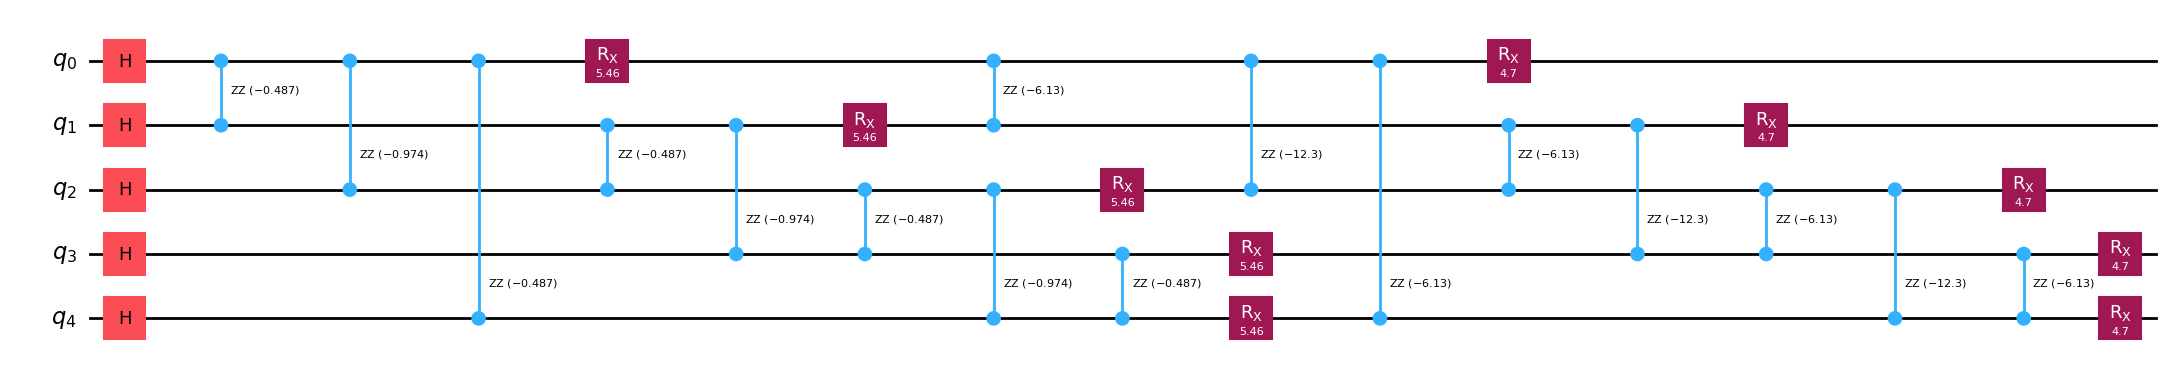

In [15]:
optimized_circuit = build_qaoa_circuit(
    G,
    gamma_opt,
    beta_opt,
    measure=False
)

optimized_circuit.draw("mpl", fold=-1)

In [16]:
SHOTS = 10000

measured_circuit = build_qaoa_circuit(
    G,
    gamma_opt,
    beta_opt,
    measure=True
)

compiled_circuit = transpile(
    measured_circuit,
    simulator,
    optimization_level=1
)

job = simulator.run(
    compiled_circuit,
    shots=SHOTS,
    seed_simulator=SEED
)

result = job.result()

counts = result.get_counts(compiled_circuit)

print("Measurement counts:")

for bitstring, count in sorted(counts.items()):
    print(bitstring, ":", count)

print("\nTotal shots:", sum(counts.values()))

Measurement counts:
00000 : 23
00001 : 6
00010 : 18
00011 : 177
00100 : 62
00101 : 214
00110 : 1060
00111 : 177
01000 : 18
01001 : 904
01011 : 183
01100 : 1056
01101 : 904
01110 : 114
01111 : 5
10000 : 3
10001 : 125
10010 : 944
10011 : 1091
10100 : 220
10101 : 1
10110 : 952
10111 : 31
11000 : 169
11001 : 1055
11010 : 193
11011 : 59
11100 : 178
11101 : 34
11110 : 5
11111 : 19

Total shots: 10000


## Convert Counts into Probabilities

After executing the quantum circuit, Qiskit returns measurement counts for each bitstring.

We convert these counts into probabilities using the empirical probability equation:

$$
\hat P(x)=\frac{n_x}{N}
$$

### Explanation

- $x$: Measurement outcome (bitstring), such as `00`, `01`, `10`, or `11`.
- $n_x$: Number of times a particular bitstring appears.
- $N$: Total number of measurement shots.
- $\hat P(x)$: Estimated probability of obtaining that bitstring.

### Example

Suppose we execute a quantum circuit with 1,000 shots and obtain the following measurement counts:

| Bitstring | Measurement Counts |
|---|---:|
| 00 | 450 |
| 01 | 200 |
| 10 | 150 |
| 11 | 200 |
| **Total** | **1,000** |

The probability of each measurement outcome is calculated as follows:

$$
\hat P(00)=\frac{450}{1000}=0.45
$$

$$
\hat P(01)=\frac{200}{1000}=0.20
$$

$$
\hat P(10)=\frac{150}{1000}=0.15
$$

$$
\hat P(11)=\frac{200}{1000}=0.20
$$

### Interpretation

The probability of obtaining `00` is 0.45 (45%), while the probability of obtaining `11` is 0.20 (20%).

The sum of all measurement probabilities should equal 1:

$$
\sum_x \hat P(x)=1
$$

**Why do we need this?**

Converting counts into probabilities allows us to understand the distribution of quantum measurement outcomes. In QAOA, these probabilities help us evaluate candidate solutions and calculate the expected Max-Cut value.

In [17]:
total_shots = sum(counts.values())

measurement_probabilities = {
    bitstring.replace(" ", ""): count / total_shots
    for bitstring, count in counts.items()
}

print("Measurement probabilities:")

for bitstring, probability in sorted(
    measurement_probabilities.items()
):

    print(
        bitstring,
        "->",
        round(probability, 5)
    )

print(
    "\nProbability sum:",
    sum(measurement_probabilities.values())
)

Measurement probabilities:
00000 -> 0.0023
00001 -> 0.0006
00010 -> 0.0018
00011 -> 0.0177
00100 -> 0.0062
00101 -> 0.0214
00110 -> 0.106
00111 -> 0.0177
01000 -> 0.0018
01001 -> 0.0904
01011 -> 0.0183
01100 -> 0.1056
01101 -> 0.0904
01110 -> 0.0114
01111 -> 0.0005
10000 -> 0.0003
10001 -> 0.0125
10010 -> 0.0944
10011 -> 0.1091
10100 -> 0.022
10101 -> 0.0001
10110 -> 0.0952
10111 -> 0.0031
11000 -> 0.0169
11001 -> 0.1055
11010 -> 0.0193
11011 -> 0.0059
11100 -> 0.0178
11101 -> 0.0034
11110 -> 0.0005
11111 -> 0.0019

Probability sum: 1.0


## Cell 16 — Calculate Expected Cut Value

After measuring the QAOA circuit, we calculate the cut value for each measured bitstring.

The expected cut value is calculated using:

$$
\hat C=\frac{1}{N}\sum_{k=1}^{N}C(x_k)
$$

### Explanation

- $N$: Total number of measurement shots.
- $x_k$: Bitstring obtained from the $k$-th measurement.
- $C(x_k)$: Cut value of the measured bitstring.
- $\hat C$: Average cut value across all measurement shots.

### Example

Suppose we execute the QAOA circuit with 5 shots and obtain these cut values:

$$
C(x_1)=3,\quad C(x_2)=2,\quad C(x_3)=3
$$

$$
C(x_4)=1,\quad C(x_5)=3
$$

The expected cut value is:

$$
\hat C=\frac{3+2+3+1+3}{5}
$$

$$
\boxed{\hat C=2.4}
$$

### Interpretation

The average cut value is 2.4. This means that the measured solutions achieve an average cut value of 2.4 across the five shots.

A higher expected cut value indicates better average Max-Cut performance.

### Why do we need this?

QAOA produces multiple measurement outcomes rather than one fixed solution. We calculate the expected cut value to evaluate the overall quality of the quantum algorithm.

We also use this value to assess whether the classical optimizer is improving the QAOA parameters.

In [18]:
def decode_qiskit_bitstring(bitstring):

    bitstring = bitstring.replace(" ", "")

    return tuple(
        int(bit)
        for bit in bitstring[::-1]
    )


def calculate_expected_cut_from_counts(
    graph,
    counts
):

    total_shots = sum(counts.values())

    weighted_sum = 0

    for bitstring, count in counts.items():

        assignment = decode_qiskit_bitstring(
            bitstring
        )

        cut_value = calculate_cut_value(
            graph,
            assignment
        )

        weighted_sum += count * cut_value

    return weighted_sum / total_shots


measured_expected_cut = calculate_expected_cut_from_counts(
    G,
    counts
)

print(
    "Measured expected cut value:",
    measured_expected_cut
)

Measured expected cut value: 7.5438


## Cell 17 — Calculate Approximation Ratio

The approximation ratio measures how close the QAOA solution is to the exact optimal solution obtained using a classical method.

It is calculated as:

$$
R=\frac{\hat C}{C^*}
$$

### Explanation

- $R$: Approximation ratio.
- $\hat C$: Expected cut value obtained from QAOA measurements.
- $C^*$: Exact optimal cut value calculated using a classical method.

### Example

Suppose:

- QAOA expected cut value = 8.
- Exact classical optimal cut value = 10.

The approximation ratio is:

$$
R=\frac{8}{10}=0.8
$$

$$
\boxed{R=0.80=80\%}
$$

### Interpretation

An approximation ratio of 0.80 means that QAOA achieves 80% of the exact optimal cut value.

- $R=1.0$: QAOA achieves the exact optimal value.
- $R=0.90$: QAOA achieves 90% of the optimal value.
- $R=0.70$: QAOA achieves 70% of the optimal value.

### Why do we need this?

QAOA is an approximate optimization algorithm. It does not always find the exact optimal solution.

The approximation ratio helps us evaluate how effectively QAOA solves the Max-Cut problem compared with the exact classical solution.

It also provides a quantitative measure for comparing different QAOA configurations, such as different circuit depths ($p$) and shot budgets.

In [19]:
approximation_ratio = (
    measured_expected_cut / exact_optimum
    if exact_optimum > 0
    else 0
)

print(
    "Measured expected cut:",
    measured_expected_cut
)

print(
    "Exact optimal cut:",
    exact_optimum
)

print(
    "Approximation ratio:",
    approximation_ratio
)

Measured expected cut: 7.5438
Exact optimal cut: 8
Approximation ratio: 0.942975


## Cell 18 — Calculate Optimal Solution Probability

The optimal solution probability measures how often QAOA produces an optimal Max-Cut solution during quantum circuit measurements.

It is calculated using:

$$
P_{\mathrm{success}}=
\sum_{x:C(x)=C^*}\hat P(x)
$$

### Explanation

- $P_{\mathrm{success}}$: Probability of obtaining an optimal solution.
- $C(x)$: Cut value of a measured bitstring.
- $C^*$: Exact optimal cut value.
- $\hat P(x)$: Estimated probability of measuring bitstring $x$.
- $x$: Measured bitstring.

The condition $C(x)=C^*$ means that we only consider measurement outcomes whose cut value equals the exact optimal cut value.

### Example

Suppose the exact classical optimal cut value is:

$$
C^*=5
$$

After executing the QAOA circuit with 1,000 shots, we obtain:

| Bitstring | Cut Value | Counts |
|---|---:|---:|
| 000 | 3 | 200 |
| 001 | 4 | 150 |
| 010 | 5 | 300 |
| 101 | 5 | 250 |
| 111 | 2 | 100 |
| **Total** | | **1,000** |

The optimal solutions are `010` and `101`, because both have a cut value equal to 5.

Their probabilities are:

$$
\hat P(010)=\frac{300}{1000}=0.30
$$

$$
\hat P(101)=\frac{250}{1000}=0.25
$$

Therefore:

$$
P_{\mathrm{success}}=0.30+0.25
$$

$$
\boxed{P_{\mathrm{success}}=0.55=55\%}
$$

### Interpretation

A success probability of 55% means that QAOA produces an optimal Max-Cut solution in 55% of the measurement shots.

### Why do we need this?

The expected cut value tells us the average solution quality, while the optimal solution probability tells us how frequently the quantum algorithm finds the exact optimal solution.

This metric helps evaluate the reliability of QAOA and compare its performance under different shot budgets and circuit configurations.

In [20]:
optimal_solution_probability = 0.0

for bitstring, count in counts.items():

    assignment = decode_qiskit_bitstring(
        bitstring
    )

    if assignment in optimal_assignments:

        optimal_solution_probability += (
            count / total_shots
        )

print(
    "Optimal solution probability:",
    optimal_solution_probability
)

print(
    "Optimal solution probability (%):",
    optimal_solution_probability * 100
)

Optimal solution probability: 0.7966000000000001
Optimal solution probability (%): 79.66000000000001


Compare QAOA and classical results


In [21]:
most_frequent_bitstring = max(
    counts,
    key=counts.get
)

most_frequent_assignment = decode_qiskit_bitstring(
    most_frequent_bitstring
)

most_frequent_cut = calculate_cut_value(
    G,
    most_frequent_assignment
)

best_measured_cut = max(
    calculate_cut_value(
        G,
        decode_qiskit_bitstring(bitstring)
    )
    for bitstring in counts
)

print("=" * 55)

print("CLASSICAL VS QAOA COMPARISON")

print("=" * 55)

print("Exact classical optimum:", exact_optimum)

print("QAOA ideal expected cut:", optimized_expected_cut)

print("QAOA sampled expected cut:", measured_expected_cut)

print("Best measured cut:", best_measured_cut)

print("Most frequent assignment:", most_frequent_assignment)

print("Approximation ratio:", approximation_ratio)

print("Optimal solution probability:", optimal_solution_probability)

CLASSICAL VS QAOA COMPARISON
Exact classical optimum: 8
QAOA ideal expected cut: 7.521935723373846
QAOA sampled expected cut: 7.5438
Best measured cut: 8
Most frequent assignment: (1, 1, 0, 0, 1)
Approximation ratio: 0.942975
Optimal solution probability: 0.7966000000000001


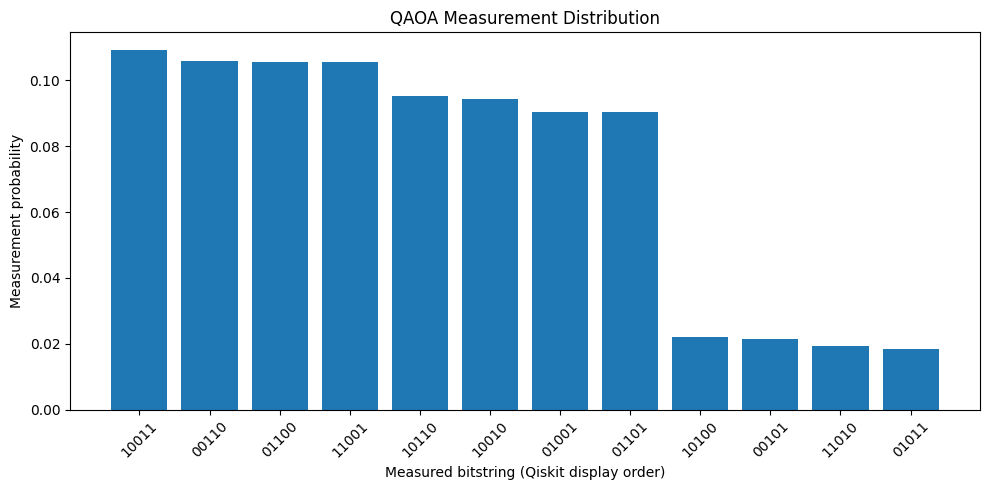

In [22]:
outcome_data = []

for bitstring, count in counts.items():

    assignment = decode_qiskit_bitstring(
        bitstring
    )

    cut_value = calculate_cut_value(
        G,
        assignment
    )

    probability = count / total_shots

    outcome_data.append({
        "bitstring": bitstring.replace(" ", ""),
        "cut_value": cut_value,
        "probability": probability
    })

outcome_data.sort(
    key=lambda item: item["probability"],
    reverse=True
)

top_outcomes = outcome_data[:12]

labels = [
    item["bitstring"]
    for item in top_outcomes
]

probabilities = [
    item["probability"]
    for item in top_outcomes
]

plt.figure(figsize=(10, 5))

plt.bar(labels, probabilities)

plt.xlabel("Measured bitstring (Qiskit display order)")

plt.ylabel("Measurement probability")

plt.title("QAOA Measurement Distribution")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

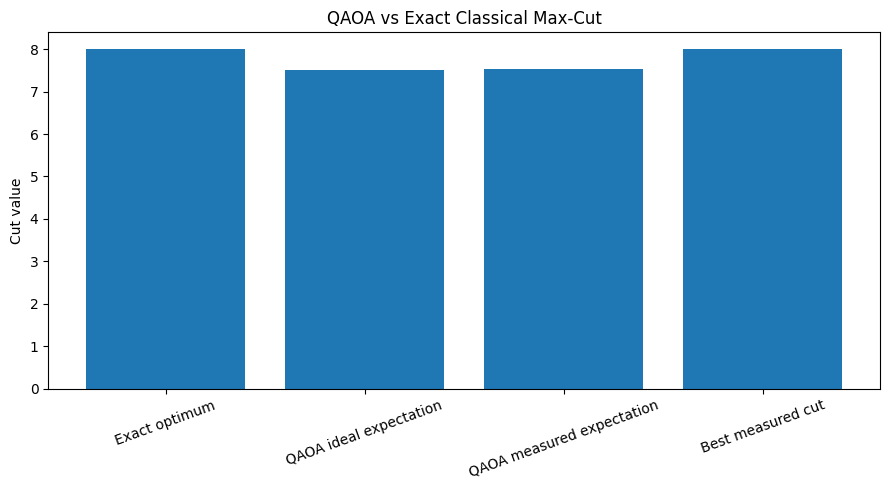

In [23]:
metrics = {
    "Exact optimum": exact_optimum,
    "QAOA ideal expectation": optimized_expected_cut,
    "QAOA measured expectation": measured_expected_cut,
    "Best measured cut": best_measured_cut
}

plt.figure(figsize=(9, 5))

plt.bar(
    list(metrics.keys()),
    list(metrics.values())
)

plt.ylabel("Cut value")

plt.title("QAOA vs Exact Classical Max-Cut")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

## 3. Research Interpretation for QFlowPilot

This experiment provides the first application-level quality
measurements for QFlowPilot.

We evaluated QAOA using an exact classical Max-Cut reference.

### Important observations

1. The exact classical solver provides the optimal cut value.
2. QAOA produces a probability distribution over possible solutions.
3. The expected cut value measures average solution quality.
4. The approximation ratio measures performance relative to
   the exact optimum.
5. Optimal solution probability measures how frequently
   optimal solutions are observed.

### Important distinction

A high expected cut value does not necessarily mean that the
optimal solution is measured frequently.

Similarly, a high optimal-solution probability and a low
measurement uncertainty describe different properties.

### Implications for a quality-aware runtime

A runtime may need to decide whether to:

- Accept the current result.
- Allocate additional measurement shots.
- Re-execute the circuit.
- Use a classical fallback.

However, this notebook does not yet implement those decisions.

Notebook 04 will study adaptive shot allocation, while
Notebook 06 will formulate quality-constrained runtime decisions.

## 4. Completion Checklist

- [ ] Qiskit and Qiskit Aer installed.
- [ ] NetworkX graph generated.
- [ ] Graph visualization completed.
- [ ] Max-Cut objective function implemented.
- [ ] Exact classical solution calculated.
- [ ] QAOA circuit constructed.
- [ ] QAOA parameters optimized.
- [ ] QAOA executed using Qiskit Aer.
- [ ] Measurement counts collected.
- [ ] Expected cut value calculated.
- [ ] Approximation ratio calculated.
- [ ] Optimal solution probability calculated.
- [ ] Classical and QAOA results compared.
- [ ] Graphs generated.
- [ ] Research observations recorded.

### Main result

This notebook establishes a Qiskit-based QAOA workload and
an application-level quality evaluator for QFlowPilot.

It uses local ideal simulation. Hardware noise, actual cloud
queue latency, and real QPU resource consumption are not
evaluated in this experiment.